## 395 Final Project: Predicting Misc Genres
- load GTZAN audio
- split data 80/20 (train/test)
- divide 30-sec recordings into 3-sec clips
- generate normalized mel spectrograms
- save spectrograms as .NPY files
- create.CSV metadata file

In [ ]:
import os, glob
from pathlib import Path
from tqdm import tqdm

import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import shutil

from sklearn.model_selection import train_test_split

SEED = 4

SR = 22050 #sample rate (samps/sec)
SEG_LEN = 3*SR #num samples in 3 second clip

DATA_DIR=Path("./music_data/genres_original")
OUT_DIR= Path("./music_data/mel_3_sec")
os.makedirs(OUT_DIR, exist_ok=True)

### Load and Split Data

In [2]:
#load CSV file info for GTZAN dataset
data = pd.read_csv("./music_data/features_3_sec.csv")

parts = data["filename"].str.split(".", expand=True)

data["genre"] = parts[0]
data["song"] = parts[0] + "." + parts[1]
data["segment"] = parts[2].astype(int)

#train/test split
songs = data[["song", "genre"]].drop_duplicates()

train_songs, test_songs = train_test_split(
    songs,
    test_size=0.2,
    stratify=songs["genre"],
    random_state=SEED
)

train_song_set = set(train_songs["song"])
test_song_set = set(test_songs["song"])

data["split"] = data["song"].apply(
    lambda song: "train" if song in train_song_set else "test"
)

### Test Gen Spectrogram for One Image

Length of clip: 30.013333333333332
Melspectrogram shape: (128, 130)


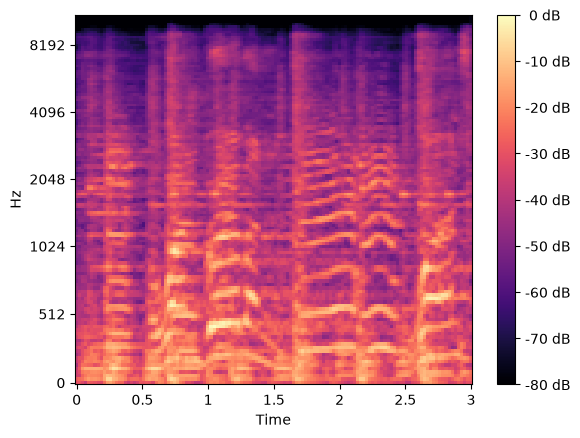

In [3]:
#test for one image
audio_samps, sr = librosa.load("./music_data/genres_original/blues/blues.00000.wav", sr=SR)
print("Length of clip:", len(audio_samps) / sr) #around 30 sec

seg = audio_samps[:3 * sr] #first 3 sec
mel = librosa.feature.melspectrogram(y=seg, sr=sr, n_fft=2048, hop_length=512, n_mels=128)
mel_db = librosa.power_to_db(mel, ref=np.max)
print("Melspectrogram shape:", mel_db.shape) #expect (128, 130)

librosa.display.specshow(mel_db, sr=sr, hop_length=512, x_axis="time", y_axis="mel")
plt.colorbar(format="%2.0f dB")
plt.show()

### Mel Spectrogram Generation

In [4]:
#function generates one normalized mel spectrogram
def gen_mel_spectrogram(segment):

    #generate spectrogram
    mel = librosa.feature.melspectrogram(y=segment,
                                         sr=SR,
                                         n_fft=2048,
                                         hop_length=512,
                                         n_mels=128
                                         )
    #convert power to db
    mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80)

    #normalize to range [0, 1]
    mel_norm = (mel_db + 80) / 80
    mel_norm = np.clip(mel_norm, 0, 1)

    return mel_norm.astype(np.float32)

In [5]:
#make spectrograms for all images
metadata_rows = []
failed = []

for path in tqdm(sorted(glob.glob(f"{DATA_DIR}/*/*.wav"))):

    #original song filename (eg "blues.00000")
    song = Path(path).stem
    genre = Path(path).parent.name

    #metadata entries for song
    song_rows = data[data["song"] == song]

    if song_rows.empty:
        print("No matching CSV entries for", song)

    try:
        audio, sr = librosa.load(path, sr=SR, mono=True)
    except Exception as e:
        failed.append((song, str(e)))
        continue

    #generate 3-sec segment
    for _, row in song_rows.iterrows():

        segment_num = int(row["segment"])

        start = segment_num * SEG_LEN
        end = (segment_num + 1) * SEG_LEN

        segment = audio[start:end]

        if len(segment) != SEG_LEN:
            failed.append((song, f"Segment {segment_num} is too short"))
            continue

        mel = gen_mel_spectrogram(segment)

        # Example: blues.00000.0.npy
        filename = row["filename"] + ".npy"

        output_path = OUT_DIR / filename
        np.save(output_path, mel)

        metadata_rows.append({
            "filename": row["filename"],
            "genre": genre,
            "song": song,
            "segment": segment_num,
            "split": row["split"],
            "spectrogram_path": str(output_path)
        })

#save processed data info to CSV
metadata = pd.DataFrame(metadata_rows)
metadata.to_csv("./music_data/metadata.csv", index=False)

print("Generated spectrograms:", len(metadata))
print("Failed segments:", len(failed))
print("Train segments:", (metadata["split"] == "train").sum())
print("Test segments:", (metadata["split"] == "test").sum())

if failed:
    print("\nFailed files:")
    for item in failed:
        print(item)

100%|██████████| 1000/1000 [01:14<00:00, 13.46it/s]

Generated spectrograms: 9980
Failed segments: 1
Train segments: 7981
Test segments: 1999

Failed files:
('jazz.00054', "Error opening 'music_data/genres_original/jazz/jazz.00054.wav': Format not recognised.")


### Check one example


Test spectrogram shape: (128, 130)
Min val: 0.0
Max_val: 1.0


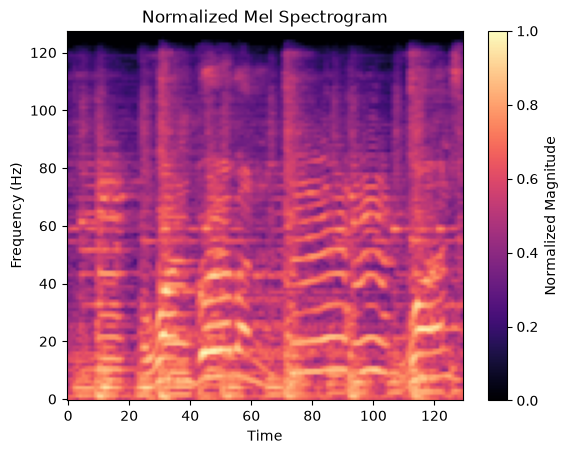

In [9]:
test_path = metadata.iloc[0]["spectrogram_path"]
test_mel = np.load(test_path)

print("\nTest spectrogram shape:", test_mel.shape)
print("Min val:", test_mel.min())
print("Max_val:", test_mel.max())

sample = np.load("./music_data/mel_3_sec/blues.00000.0.wav.npy")

plt.figure()
plt.imshow(sample, aspect="auto", origin="lower", cmap="magma")
plt.title("Normalized Mel Spectrogram")
plt.xlabel("Time")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Normalized Magnitude")
plt.show()

